# Artificial Intelligence Lab 07
## Search Algorithms in Python

**Course:** Artificial Intelligence (CSC-3602)  
**University:** University of South Asia, Lahore  
**Instructor:** Muhammad Waqas Ishaq  
**Course alignment:** CLO-2 (Apply) and CLO-5 (Develop simple AI solutions with tools)

## Connection with the lecture notes

- **Problem Formulation:** initial state, actions, transition model, goal test, path cost, state space and abstraction.
- **Uninformed Search (Lectures 04–05):** BFS, DFS, UCS, frontier, explored set, completeness, optimality, time and space.
- **Informed Search (Lecture 06):** heuristic values `h(n)`, Greedy Best-First Search, A*, admissibility and consistency.

## What you will do in this lab

In the lectures, you traced search algorithms by hand. In this lab, you will complete guided Python code and compare how the algorithms behave on the same problems. BFS is provided as a reference implementation; you will complete the main logic for DFS, UCS, Greedy Best-First Search and A*.

You will use the Lahore–Islamabad and Lahore–Multan road maps from the lecture examples, then apply heuristic search to the 8-puzzle and a grid maze.

**Delivery plan:** This notebook is designed for **two separate 90-minute lab sessions**. Complete Session 1 through Task 4.2, then begin Session 2 at Task 4.3.

| Session | Part | Topic / tasks | Suggested time |
|---|---|---|---|
| **1** | 0 | Setup | 5 min |
| **1** | 1 | Python warm-up: queue, stack, priority queue (1.1–1.3) | 15 min |
| **1** | 2 | A problem as code: graph, path cost (2.1–2.2) | 15 min |
| **1** | 3 | Uninformed search: BFS, DFS, UCS (3.1–3.4) | 35 min |
| **1** | 4A | Greedy and A* implementation (4.1–4.2) | 20 min |
|  |  | **Session 1 total** | **90 min** |
| **2** | 4B | Compare algorithms and heuristic safety (4.3–4.4 core; 4.5–4.6 guided) | 20 min |
| **2** | 5 | The 8-puzzle: comparing heuristics (5.1–5.2) | 25 min |
| **2** | 6 | Maze challenge (6.1–6.2 core; 6.3 extension) | 25 min |
| **2** | 7 | Reflection and submission | 10 min |
| **2** | — | Questions, checkpoint and catch-up buffer | 10 min |
|  |  | **Session 2 total** | **90 min** |

**Instructor note:** The 8-puzzle and maze sections are guided challenges for fundamentals-level students. If the class needs more time, complete Task 6.3 as an extension after the core tasks.

## How to work

- Run the cells **from top to bottom** using **Shift + Enter**. Later cells need the earlier ones.
- In fill-in cells, replace each `BLANK` with the correct word, method or number. Keep the rest of the code unchanged.
- Run each test cell after completing its task. The notebook reports **PASS**, **CHECK** or **NOT COMPLETE**.
- For written questions, edit the answer line in the markdown cell and use your own words.
- The core search algorithms use only Python's standard library. The optional road-map drawings use `matplotlib` if it is installed; the notebook continues to work without it.


**Instructor output preview:** This copy has the student `BLANK` entries completed so you can inspect expected outputs. Use the separate student notebook for class submissions.

## A quick note before you start

You do **not** need to be an expert in Python. Most of the code is already written. Your job is to replace the `BLANK` markers using the ideas from the lectures.

**Example**
```python
first = q.BLANK()  # Which method removes an item from the FRONT: popleft or pop?
```
Replace `BLANK` with `popleft`, so the line becomes `first = q.popleft()`. Then press **Shift + Enter** and read the test message.

**If you get stuck**
1. Read the comment beside the blank. It explains what kind of value or method is needed.
2. Compare the algorithm with the BFS reference code in Part 3.
3. If an error mentions `BLANK`, check whether a placeholder is still unfilled. Otherwise, check spelling, brackets and indentation.
4. If you are stuck for more than five minutes, discuss the step with a partner and then ask the instructor.

**The main idea:** each search algorithm uses a frontier, but the rule for choosing the next state changes:

- BFS: queue (FIFO)
- DFS: stack (LIFO)
- UCS: lowest path cost `g`
- Greedy Best-First: lowest heuristic `h`
- A*: lowest `f = g + h`


---
# Part 0 — Setup
Run the next two cells. They load the tools and the maps we used in the lectures. **Write your name and roll number first.**


In [9]:
# Run this cell first. Enter your name and roll number before submitting.
from collections import deque, namedtuple
import heapq

STUDENT_NAME = ""  # Write your name here
ROLL_NO = ""       # Write your roll number here

# Each search algorithm returns one Result object:
# found        - whether a goal was reached
# path         - states from start to goal
# cost         - total path cost
# checked      - states taken from the frontier, in order
# max_frontier - largest frontier size (a rough measure of memory)
Result = namedtuple("Result", "found path cost checked max_frontier")

RESULTS = {}  # Test results are collected here

def run_test(name, fn):
    """Run one test and print a clear status message."""
    try:
        fn()
        print(f"[PASS] {name}: passed")
        RESULTS[name] = True
    except (NotImplementedError, NameError):
        print(f"[NOT COMPLETE] {name}: check for any remaining BLANK values, then run again")
        RESULTS[name] = False
    except AssertionError as e:
        print(f"[CHECK] {name}: {e}")
        RESULTS[name] = False
    except AttributeError as e:
        if "BLANK" in str(e):
            print(f"[NOT COMPLETE] {name}: replace the remaining BLANK value, then run again")
            RESULTS[name] = False
        else:
            print(f"[ERROR] {name}: {e}")
            RESULTS[name] = False
    except Exception as e:
        print(f"[ERROR] {name}: {type(e).__name__}: {e}")
        RESULTS[name] = False

print("Setup complete. Good luck,", STUDENT_NAME or "student", "!")


Setup complete. Good luck, student !


In [10]:
# ===== The problem interface and the maps from our lectures =====
class GraphProblem:
    """A road-map problem. A search algorithm only needs three things from a problem:
         problem.start            -> the initial state
         problem.is_goal(state)   -> True if state is a goal
         problem.successors(state)-> list of (next_state, step_cost)   (alphabetical order)
    """
    def __init__(self, graph, start, goal):
        self.graph, self.start, self.goal = graph, start, goal
    def is_goal(self, state):
        return state == self.goal
    def successors(self, state):
        return sorted(self.graph[state])

def make_graph(edges):
    """edges = [(city_a, city_b, km), ...]  ->  dict {city: [(neighbour, km), ...]}  (roads work both ways)"""
    g = {}
    for a, b, w in edges:
        g.setdefault(a, []).append((b, w))
        g.setdefault(b, []).append((a, w))
    return g

def build_path(parent, state):
    """Follows the parent links back to the start and returns the path start -> state."""
    path = [state]
    while parent[state] is not None:
        state = parent[state]
        path.append(state)
    return path[::-1]

# --- Search map: Lahore -> Islamabad (road cost in km) ---
LAHORE = make_graph([("Lahore","Gujranwala",70), ("Lahore","Sialkot",40), ("Gujranwala","Gujrat",60),
                     ("Gujranwala","Jhelum",140), ("Sialkot","Gujrat",50), ("Gujrat","Jhelum",90), ("Jhelum","Islamabad",125)])
# Illustrative heuristic estimates inspired by straight-line distance to Islamabad; these are simplified exercise values, not measured geographic distances.
H_LAHORE = {"Lahore":180, "Gujranwala":130, "Sialkot":200, "Gujrat":160, "Jhelum":100, "Islamabad":0}

# --- Lecture 06 activity map: Lahore -> Multan ---
MULTAN = make_graph([("Lahore","Okara",110), ("Lahore","Faisalabad",130), ("Okara","Sahiwal",50), ("Faisalabad","Khanewal",160),
                     ("Faisalabad","Sahiwal",110), ("Sahiwal","Multan",140), ("Khanewal","Multan",50)])
H_MULTAN = {"Lahore":250, "Okara":170, "Faisalabad":155, "Sahiwal":120, "Khanewal":45, "Multan":0}

# --- Uninformed Search examples from Lectures 04–05 ---
TREE = make_graph([("A","B",1),("A","C",1),("B","D",1),("B","E",1),("C","F",1),("C","G",1)])      # BFS/DFS tree
FARE = make_graph([("Home","Metro",10),("Home","Bus",50),("Home","Rickshaw",150),               # UCS fare example (Rs)
                   ("Metro","Campus",100),("Bus","Campus",50),("Rickshaw","Campus",50)])
FRIENDS = make_graph([("Ali","Sara",1),("Ali","Bilal",1),("Sara","Maha",1),("Bilal","Zain",1),
                      ("Maha","Hina",1),("Zain","Omar",1),("Omar","Hina",1)])                       # friend chains

# --- Drawing helper (uses matplotlib; skipped quietly if it is not installed) ---
POS = {
    "LAHORE": {"Lahore":(0,2),"Gujranwala":(2,4),"Sialkot":(2,0),"Gujrat":(4,2),"Jhelum":(6,4),"Islamabad":(8,2.4)},
    "MULTAN": {"Lahore":(0,2),"Okara":(2,4),"Faisalabad":(2,0),"Sahiwal":(5,4),"Khanewal":(5,0),"Multan":(8,2)},
    "FARE":   {"Home":(0,2),"Metro":(3,4),"Bus":(3,2),"Rickshaw":(3,0),"Campus":(6,2)},
}
def draw_graph(graph, pos, path=None, title="", h=None):
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("(matplotlib not available - skipping the picture)"); return
    fig, ax = plt.subplots(figsize=(8, 3.6))
    seen = set()
    for a in graph:
        for b, w in graph[a]:
            if (b, a) in seen: continue
            seen.add((a, b))
            on = path and any((a, b) == p or (b, a) == p for p in zip(path, path[1:]))
            ax.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]], color="#00B8A0" if on else "#A9A5D6", lw=4 if on else 1.5, zorder=1)
            ax.text((pos[a][0]+pos[b][0])/2, (pos[a][1]+pos[b][1])/2, str(w), ha="center", va="center", fontsize=9,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="#DAD7F0"), zorder=3)
    for n, (x, y) in pos.items():
        ax.scatter([x], [y], s=900, color="#5B4FBF", zorder=2)
        ax.text(x, y-0.45, n, ha="center", va="top", fontsize=9, fontweight="bold")
        if h: ax.text(x, y+0.42, f"h={h[n]}", ha="center", fontsize=8, color="#0B8F7B")
    ax.set_title(title); ax.axis("off"); plt.show()

# --- Table helper: compares all five algorithms on one problem ---
def compare(problem, h=None):
    print(f"{'Algorithm':<9}{'Cost':>6}{'Checked':>9}{'MaxFrontier':>13}   Path")
    runs = [("BFS", lambda: bfs(problem)), ("DFS", lambda: dfs(problem)), ("UCS", lambda: ucs(problem))]
    if h is not None:
        hf = (lambda s: h[s]) if isinstance(h, dict) else h
        runs += [("Greedy", lambda: greedy(problem, hf)), ("A*", lambda: astar(problem, hf))]
    for name, run in runs:
        try:
            r = run()
        except (NotImplementedError, NameError, AttributeError):
            print(f"{name:<9}{'-':>6}   (will work after you finish its task)"); continue
        p = " -> ".join(map(str, r.path)) if len(r.path) <= 8 else f"({len(r.path)-1} steps)"
        print(f"{name:<9}{r.cost:>6}{len(r.checked):>9}{r.max_frontier:>13}   {p}")
print("Maps loaded: LAHORE, MULTAN, TREE, FARE, FRIENDS")


Maps loaded: LAHORE, MULTAN, TREE, FARE, FRIENDS


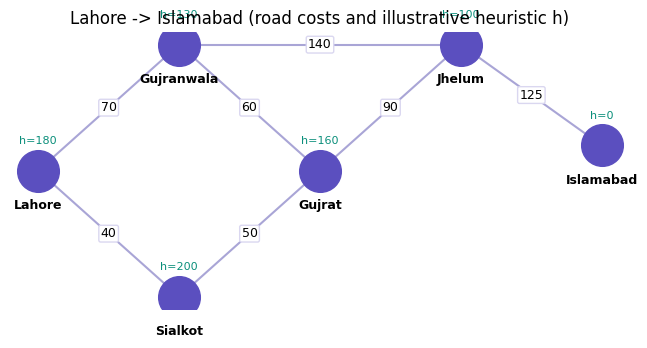

In [11]:
# Look at the Lahore -> Islamabad map (green labels show the illustrative heuristic h)
draw_graph(LAHORE, POS["LAHORE"], title="Lahore -> Islamabad (road costs and illustrative heuristic h)", h=H_LAHORE)


---
# Part 1 — Python warm-up: the three containers behind every search
Every search algorithm is the **same recipe** with a different *frontier* (the waiting list of states):

| Algorithm | Frontier is a… | Python tool | Take next from… |
|---|---|---|---|
| BFS | **queue** (first in, first out) | `collections.deque` | the front: `popleft()` |
| DFS | **stack** (last in, first out) | a normal `list` | the end: `pop()` |
| UCS / Greedy / A* | **priority queue** | `heapq` | the smallest priority: `heappop()` |

## Task 1.1 — Queue (FIFO)
Put the letters `"A"`, `"B"`, `"C"` into a `deque`, then remove **two** items from the front. Return the list of the two removed items (in the order removed).


In [12]:
def queue_demo():
    """Return the two items removed from the FRONT of a queue holding A, B, C."""
    q = deque()
    q.append("A")
    q.append("B")
    q.append("C")
    first  = q.popleft()     # which deque method removes from the FRONT?  (popleft  or  pop)
    second = q.popleft()     # same method again
    return [first, second]


In [13]:
def test_1_1():
    assert queue_demo() == ["A", "B"], f"expected ['A', 'B'] (first in, first out) but got {queue_demo()}"
run_test("Task 1.1 Queue", test_1_1)


[PASS] Task 1.1 Queue: passed


## Task 1.2 — Stack (LIFO)
Push `1`, `2`, `3` onto a stack (a list, using `append`), then `pop()` **two** items. Return the two popped items in order.


In [14]:
def stack_demo():
    """Return the two items popped from a stack after pushing 1, 2, 3."""
    s = []
    s.append(1)
    s.append(2)
    s.append(3)
    first  = s.pop()     # a list method that removes the LAST item (pop  or  popleft?)
    second = s.pop()     # same method again
    return [first, second]


In [15]:
def test_1_2():
    assert stack_demo() == [3, 2], f"expected [3, 2] (last in, first out) but got {stack_demo()}"
run_test("Task 1.2 Stack", test_1_2)


[PASS] Task 1.2 Stack: passed


## Task 1.3 — Priority queue
A priority queue always gives the **smallest** item first. With `heapq` we store tuples `(priority, name)`.
Push `(50,"Bus")`, `(10,"Metro")`, `(150,"Rickshaw")` into a heap and return the names in the order they come out.


In [16]:
def heap_demo():
    """Return the names popped from a heap holding (50,'Bus'), (10,'Metro'), (150,'Rickshaw')."""
    heap = []
    heapq.heappush(heap, (50, "Bus"))
    heapq.heappush(heap, (10, "Metro"))
    heapq.heappush(heap, (150, "Rickshaw"))
    names = []
    for _ in range(3):
        item = heapq.heappop(heap)     # heapq function that removes the SMALLEST item  (heappop / heappush)
        names.append(item[1])      # item = (priority, name) -> we want the name
    return names


In [17]:
def test_1_3():
    assert heap_demo() == ["Metro", "Bus", "Rickshaw"], f"expected ['Metro', 'Bus', 'Rickshaw'] (smallest first) but got {heap_demo()}"
run_test("Task 1.3 Priority queue", test_1_3)


[PASS] Task 1.3 Priority queue: passed


---
# Part 2 — A problem as code (Problem Formulation → Python)
In the Problem Formulation lecture, a problem had: **initial state, actions, transition model, goal test, and path cost**. In code, our `GraphProblem` offers exactly that:

| Problem-formulation idea | In the code |
|---|---|
| Initial state | `problem.start` |
| Actions + transition model | `problem.successors(state)` → list of `(next_state, step_cost)` |
| Goal test | `problem.is_goal(state)` |
| Path cost | the sum of the step costs along a path (Task 2.1) |


In [18]:
pb = GraphProblem(LAHORE, "Lahore", "Islamabad")
print("start       :", pb.start)
print("successors  :", pb.successors("Lahore"))
print("is_goal(Jhelum)    :", pb.is_goal("Jhelum"))
print("is_goal(Islamabad) :", pb.is_goal("Islamabad"))


start       : Lahore
successors  : [('Gujranwala', 70), ('Sialkot', 40)]
is_goal(Jhelum)    : False
is_goal(Islamabad) : True


## Task 2.1 — Path cost
Complete `path_cost(graph, path)` (1 blank) that adds up the road costs along a path (a list of cities).
Example: `["Lahore", "Sialkot"]` costs 40.


In [19]:
def path_cost(graph, path):
    """Total cost of travelling along `path` (list of cities) in `graph`."""
    total = 0
    for a, b in zip(path, path[1:]):          # a, b = two cities next to each other on the path
        road_cost = dict(graph[a])[b]         # (given) cost of the road a - b
        total = total + road_cost                   # add the cost of this road  (which variable?)
    return total


In [20]:
def test_2_1():
    assert path_cost(LAHORE, ["Lahore", "Sialkot"]) == 40, "Lahore -> Sialkot should cost 40"
    assert path_cost(LAHORE, ["Lahore","Gujranwala","Jhelum","Islamabad"]) == 335, "Lahore->Gujranwala->Jhelum->Islamabad should be 70+140+125 = 335"
    assert path_cost(LAHORE, ["Lahore","Sialkot","Gujrat","Jhelum","Islamabad"]) == 305, "the cheapest route should be 40+50+90+125 = 305"
    assert path_cost(LAHORE, ["Lahore"]) == 0, "a path with one city costs 0"
run_test("Task 2.1 Path cost", test_2_1)


[PASS] Task 2.1 Path cost: passed


## Task 2.2 — Formulate your own map
A student walks from the **Hostel** to the **Library**. Distances in minutes:

| Road | Minutes |
|---|---|
| Hostel – Cafe | 4 |
| Hostel – Gate | 7 |
| Cafe – Lab | 5 |
| Cafe – Library | 12 |
| Gate – Lab | 1 |
| Lab – Library | 6 |

Complete `CAMPUS` — replace the 4 blanks with the missing roads, then use `path_cost` to find the cost of the route `Hostel → Gate → Lab → Library`.
**Question:** list two other routes from Hostel to Library and their costs. Which of the three is cheapest?


In [21]:
# Two roads are written for you. Replace each BLANK with a road like ("Cafe","Lab",5)  (look at the table above)
CAMPUS = make_graph([("Hostel","Cafe",4), ("Hostel","Gate",7), ("Cafe","Lab",5), ("Cafe","Library",12), ("Gate","Lab",1), ("Lab","Library",6)])


In [22]:
def test_2_2():
    assert CAMPUS is not None, "CAMPUS is still None - build it with make_graph([...])"
    assert sorted(CAMPUS["Hostel"]) == [("Cafe", 4), ("Gate", 7)], "Hostel should connect to Cafe (4) and Gate (7)"
    assert path_cost(CAMPUS, ["Hostel","Gate","Lab","Library"]) == 14, "Hostel->Gate->Lab->Library should be 7+1+6 = 14"
    assert len(CAMPUS) == 5, "the map has 5 places"
run_test("Task 2.2 Campus map", test_2_2)


[PASS] Task 2.2 Campus map: passed


**Your answer (Task 2.2):** &nbsp; Route 1: ______ cost ___ &nbsp;|&nbsp; Route 2: ______ cost ___ &nbsp;|&nbsp; Cheapest: ______


---
# Part 3 — Uninformed (blind) search
All three algorithms below use the **same recipe** from the Uninformed Search lectures (Lectures 04–05):

1. Put the start state in the **frontier**.
2. **Take** a state from the frontier. *Is it the goal?* → stop and rebuild the path.
3. Mark it as **explored** and add its unexplored neighbours to the frontier.
4. Repeat.

Only the **frontier type and selection rule** change. We test for the goal when a state is **taken from the frontier** (the “Goal?” column in our trace tables).

| Algorithm | What it selects next | Main point from the lecture |
|---|---|---|
| BFS | Oldest state in the queue | Finds the fewest-step path; it finds the cheapest path only when every step has the same cost. |
| DFS | Newest state in the stack | Goes deep before backtracking; it is not guaranteed to find the cheapest path. |
| UCS | State with the lowest cost-so-far `g` | Finds a cheapest path for the positive road costs used in this lab. |

In the comparison tables, **checked** is the number of states taken from the frontier before stopping. **MaxFrontier** is the largest waiting list observed, a rough space-use indicator. These are practical measurements for this lab, not formal complexity formulas.

## 3.1 BFS — worked example (read it, then run it)
BFS uses a **queue**: the oldest state is taken first, so it explores level by level.


In [23]:
def bfs(problem):
    start = problem.start
    parent = {start: None}          # how we reached each state (to rebuild the path later)
    cost = {start: 0}               # cost so far to each state
    frontier = deque([start])       # the QUEUE
    explored = set()
    checked = []                    # order in which states were taken from the frontier
    max_frontier = 1
    while frontier:
        state = frontier.popleft()  # take from the FRONT
        checked.append(state)
        if problem.is_goal(state):  # goal test when TAKEN from the frontier
            return Result(True, build_path(parent, state), cost[state], checked, max_frontier)
        explored.add(state)
        for nxt, step in problem.successors(state):
            if nxt not in explored and nxt not in parent:   # new state: not explored, not already waiting
                parent[nxt] = state
                cost[nxt] = cost[state] + step
                frontier.append(nxt)                        # add at the BACK
        max_frontier = max(max_frontier, len(frontier))
    return Result(False, [], 0, checked, max_frontier)

def show(name, r):
    print(f"{name}: found={r.found}  cost={r.cost}  checked({len(r.checked)})={r.checked}")
    print("   path:", " -> ".join(map(str, r.path)))

# Uninformed Search example tree: goal C. BFS checks A, B, C (3 nodes).
show("BFS on TREE (goal C)", bfs(GraphProblem(TREE, "A", "C")))
show("BFS on LAHORE map   ", bfs(GraphProblem(LAHORE, "Lahore", "Islamabad")))


BFS on TREE (goal C): found=True  cost=1  checked(3)=['A', 'B', 'C']
   path: A -> C
BFS on LAHORE map   : found=True  cost=335  checked(6)=['Lahore', 'Gujranwala', 'Sialkot', 'Gujrat', 'Jhelum', 'Islamabad']
   path: Lahore -> Gujranwala -> Jhelum -> Islamabad


In [24]:
def test_3_1():
    r = bfs(GraphProblem(TREE, "A", "C"))
    assert r.checked == ["A", "B", "C"], "BFS on the tree with goal C should check A, B, C"
    r = bfs(GraphProblem(LAHORE, "Lahore", "Islamabad"))
    assert r.path == ["Lahore","Gujranwala","Jhelum","Islamabad"] and r.cost == 335, "BFS finds the FEWEST STEPS route (335 km), not the cheapest"
run_test("Task 3.1 BFS (given) works", test_3_1)


[PASS] Task 3.1 BFS (given) works: passed


**Question 3.1:** BFS returned a route of **335 km**, but a **305 km** route exists. Why did BFS not find the cheaper one?
> **Your answer:** _______________________________________________


## Task 3.2 — Degrees of separation (BFS in real life)
In the Uninformed Search lectures (04–05), we used BFS for *friend chains*. Look at the friend network:


In [25]:
show("BFS: Ali -> Hina", bfs(GraphProblem(FRIENDS, "Ali", "Hina")))


BFS: Ali -> Hina: found=True  cost=3  checked(7)=['Ali', 'Bilal', 'Sara', 'Zain', 'Maha', 'Omar', 'Hina']
   path: Ali -> Sara -> Maha -> Hina


Complete `degrees_of_separation(graph, a, b)` (1 blank) = the **number of friendship steps** between `a` and `b` (use `bfs`). If there is no connection, return `None`.


In [26]:
def degrees_of_separation(graph, a, b):
    """Fewest friendship steps between a and b (None if not connected)."""
    r = bfs(GraphProblem(graph, a, b))
    if r.found:
        return len(r.path) - 1     # people on the path minus ?  (3 people = 2 steps)
    else:
        return None


In [27]:
def test_3_2():
    assert degrees_of_separation(FRIENDS, "Ali", "Hina") == 3, "Ali -> Sara -> Maha -> Hina is 3 steps"
    assert degrees_of_separation(FRIENDS, "Ali", "Ali") == 0, "a person is 0 steps from themselves"
    island = make_graph([("P","Q",1)]); island["R"] = []
    assert degrees_of_separation(island, "P", "R") is None, "no connection should return None"
run_test("Task 3.2 Degrees of separation", test_3_2)


[PASS] Task 3.2 Degrees of separation: passed


## Task 3.3 — Depth-First Search (DFS)
DFS uses a **stack**: the **newest** state is taken first, so it dives deep and only comes back when stuck.

Complete `dfs(problem)` — fill the **3 blanks** (`BLANK`). Compare with the BFS code above. The differences are:
- the frontier is a **list used as a stack** (`append` to add, `pop()` to take the newest);
- keep `(state, parent, cost)` on the stack, mark a state **explored when you take it** (skip it if already explored);
- push neighbours in **reversed** order so that the alphabetically first neighbour is taken first (this matches our lecture traces).


In [28]:
def dfs(problem):
    """Depth-first search with an explored set. 3 blanks (BLANK) to fill."""
    stack = [(problem.start, None, 0)]       # the STACK holds (state, parent, cost so far)
    explored, parent, checked = set(), {}, []
    max_frontier = 1
    while stack:
        state, par, g = stack.pop()          # BLANK 1: take the NEWEST item  (pop  or  popleft?)
        if state in explored:
            continue
        parent[state] = par
        explored.add(state)
        checked.append(state)
        if problem.is_goal(state):
            return Result(True, build_path(parent, state), g, checked, max_frontier)
        for nxt, step in reversed(problem.successors(state)):   # BLANK 2: go through the neighbours BACKWARDS  (reversed / sorted)
            if nxt not in explored:
                stack.append((nxt, state, g + step))        # BLANK 3: new cost = cost so far + ?  (step / g)
        max_frontier = max(max_frontier, len(stack))
    return Result(False, [], 0, checked, max_frontier)


In [29]:
def test_3_3():
    r = dfs(GraphProblem(TREE, "A", "C"))
    assert r.checked == ["A","B","D","E","C"], f"DFS on the tree (goal C) should check A, B, D, E, C but checked {r.checked}"
    r = dfs(GraphProblem(TREE, "A", "D"))
    assert r.checked == ["A","B","D"], f"DFS with goal D should check A, B, D but checked {r.checked}"
    r = dfs(GraphProblem(LAHORE, "Lahore", "Islamabad"))
    assert r.cost == 345 and r.path == ["Lahore","Gujranwala","Gujrat","Jhelum","Islamabad"], f"DFS on the Lahore map should give 345 km via Gujranwala, Gujrat, Jhelum but got {r.cost}: {r.path}"
run_test("Task 3.3 DFS", test_3_3)


[PASS] Task 3.3 DFS: passed


In [30]:
# Compare BFS and DFS on the Lahore -> Islamabad map
compare(GraphProblem(LAHORE, "Lahore", "Islamabad"))


Algorithm  Cost  Checked  MaxFrontier   Path
BFS         335        6            3   Lahore -> Gujranwala -> Jhelum -> Islamabad
DFS         345        5            4   Lahore -> Gujranwala -> Gujrat -> Jhelum -> Islamabad
UCS           -   (will work after you finish its task)


**Question 3.3a:** On the tree with goal **C**, BFS checked 3 nodes and DFS checked 5. With goal **D**, BFS checked 4 and DFS checked 3. Is DFS always faster or always slower than BFS? Explain.
> **Your answer:** _______________________________________________

**Question 3.3b:** DFS found a **345 km** route on the Lahore map. Why can DFS return a long (and expensive) route even though it *does* reach the goal?
> **Your answer:** _______________________________________________


## Task 3.4 — Uniform-Cost Search (UCS)
UCS uses a **priority queue** ordered by the **cost so far** `g`. The cheapest state is always taken first, so UCS finds the **cheapest** route (when every road costs more than 0).

Complete `ucs(problem)` — fill the **3 blanks** (`BLANK`). Hints:
- frontier = a heap of `(g, state)` entries; take with `heapq.heappop`;
- keep `best_g[state]` = cheapest cost found so far, and `parent[state]`;
- when you find a **cheaper** way to a state that is already waiting, **update** it (push the new entry; the old, more expensive entry will be skipped later because the state is explored by then);
- test for the goal when the state is **taken** (not when generated). Remember the trace in the lecture: Campus appeared with cost 110 first, but 100 was cheaper!


In [31]:
def ucs(problem):
    """Uniform-cost search. 3 blanks (BLANK) to fill."""
    start = problem.start
    frontier = [(0, start)]                 # PRIORITY QUEUE of (g, state)
    best_g, parent = {start: 0}, {start: None}
    explored, checked = set(), []
    max_frontier = 1
    while frontier:
        g, state = heapq.heappop(frontier)      # BLANK 1: take the CHEAPEST  (heappop / heappush)
        if state in explored:               # an old, more expensive entry: skip it
            continue
        explored.add(state)
        checked.append(state)
        if problem.is_goal(state):          # goal test when TAKEN, never earlier
            return Result(True, build_path(parent, state), g, checked, max_frontier)
        for nxt, step in problem.successors(state):
            new_g = g + step                 # BLANK 2: cost to reach nxt = g + ?  (step)
            if nxt not in explored and (nxt not in best_g or new_g < best_g[nxt]):
                best_g[nxt], parent[nxt] = new_g, state
                heapq.heappush(frontier, (new_g, nxt))   # BLANK 3: the priority is the cost so far  (new_g)
        max_frontier = max(max_frontier, len(frontier))
    return Result(False, [], 0, checked, max_frontier)


In [32]:
def test_3_4():
    r = ucs(GraphProblem(FARE, "Home", "Campus"))
    assert r.path == ["Home","Bus","Campus"] and r.cost == 100, f"cheapest fare is Home -> Bus -> Campus = Rs 100, you got Rs {r.cost}: {r.path}"
    assert r.checked == ["Home","Metro","Bus","Campus"], f"lecture trace: Home, Metro, Bus, Campus - you checked {r.checked}"
    r = ucs(GraphProblem(LAHORE, "Lahore", "Islamabad"))
    assert r.cost == 305 and r.path == ["Lahore","Sialkot","Gujrat","Jhelum","Islamabad"], f"UCS should find the 305 km route, you got {r.cost}"
    r = ucs(GraphProblem(MULTAN, "Lahore", "Multan"))
    assert r.cost == 300, f"UCS on the Multan map should give 300 km, you got {r.cost}"
run_test("Task 3.4 UCS", test_3_4)


[PASS] Task 3.4 UCS: passed


Algorithm  Cost  Checked  MaxFrontier   Path
BFS         335        6            3   Lahore -> Gujranwala -> Jhelum -> Islamabad
DFS         345        5            4   Lahore -> Gujranwala -> Gujrat -> Jhelum -> Islamabad
UCS         305        6            2   Lahore -> Sialkot -> Gujrat -> Jhelum -> Islamabad

Algorithm  Cost  Checked  MaxFrontier   Path
BFS         340        6            3   Lahore -> Faisalabad -> Khanewal -> Multan
DFS         340        4            3   Lahore -> Faisalabad -> Khanewal -> Multan
UCS         300        6            2   Lahore -> Okara -> Sahiwal -> Multan


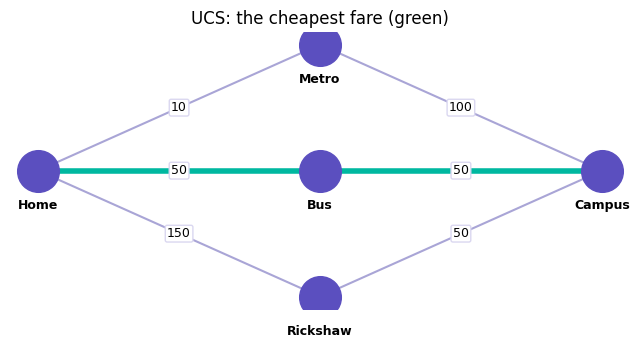

In [33]:
compare(GraphProblem(LAHORE, "Lahore", "Islamabad"))
print()
compare(GraphProblem(MULTAN, "Lahore", "Multan"))
draw_graph(FARE, POS["FARE"], path=["Home","Bus","Campus"], title="UCS: the cheapest fare (green)")


**Question 3.4a:** In the fare example UCS first saw Campus with cost 110 (via Metro), but it did **not** stop there. Why not?
> **Your answer:** _______________________________________________

**Question 3.4b:** Look at the three tables. Which of BFS / DFS / UCS always found the cheapest route on both maps? Which one needed the *most* checks?
> **Your answer:** _______________________________________________


---
# Part 4 — Informed search: using a hint
Now every state has a hint `h(n)`: our **estimate** of the remaining cost to the goal (`h(goal) = 0`). In code we pass `h` as a function: `h(state) -> number`.

| Algorithm | Priority of a state | Uses |
|---|---|---|
| UCS | `g` | real cost so far only |
| **Greedy Best-First** | `h` | the hint only |
| **A\*** | `g + h` | real cost + hint |

## Task 4.1 — Greedy Best-First Search
Greedy always takes the state that **looks closest to the goal** (smallest `h`).

Complete `greedy(problem, h)` — fill the **3 blanks** (`BLANK`). Hints:
- frontier = heap of `(h(state), state)`;
- Greedy **does not update** a state once it has been added — the first way we find to a state is kept (`if nxt not in explored and nxt not in parent`);
- keep `cost[state]` so the Result shows the real cost of the path found (Greedy does not use it to decide).


In [34]:
def greedy(problem, h):
    """Greedy best-first search. 3 blanks (BLANK) to fill. Priority = the HINT only."""
    start = problem.start
    frontier = [(h(start), start)]        # BLANK 1: priority of the start state = its hint  (h)
    parent, cost = {start: None}, {start: 0}
    explored, checked = set(), []
    max_frontier = 1
    while frontier:
        _, state = heapq.heappop(frontier)  # state with the smallest hint
        if state in explored:
            continue
        explored.add(state)
        checked.append(state)
        if problem.is_goal(state):
            return Result(True, build_path(parent, state), cost[state], checked, max_frontier)
        for nxt, step in problem.successors(state):
            if nxt not in explored and nxt not in parent:    # first way found is kept
                parent[nxt], cost[nxt] = state, cost[state] + step   # BLANK 2: add the road cost  (step)
                heapq.heappush(frontier, (h(nxt), nxt))           # BLANK 3: priority = hint of nxt  (h)
        max_frontier = max(max_frontier, len(frontier))
    return Result(False, [], 0, checked, max_frontier)


In [35]:
def test_4_1():
    r = greedy(GraphProblem(LAHORE, "Lahore", "Islamabad"), lambda s: H_LAHORE[s])
    assert r.checked == ["Lahore","Gujranwala","Jhelum","Islamabad"], f"lecture trace: Lahore, Gujranwala, Jhelum, Islamabad - you checked {r.checked}"
    assert r.cost == 335, f"Greedy should return the 335 km route (it is fooled), you got {r.cost}"
    r = greedy(GraphProblem(MULTAN, "Lahore", "Multan"), lambda s: H_MULTAN[s])
    assert r.path == ["Lahore","Faisalabad","Khanewal","Multan"] and r.cost == 340, f"Greedy on the Multan map should give 340 km via Faisalabad and Khanewal, you got {r.cost}"
run_test("Task 4.1 Greedy", test_4_1)


[PASS] Task 4.1 Greedy: passed


## Task 4.2 — A* Search
A* combines both: priority **f = g + h** (real cost so far + estimated cost to go).

Complete `astar(problem, h)` — fill the **1 blank** (`BLANK`). **Hint:** A* is *exactly UCS* with one change: the heap priority is `new_g + h(next)` instead of `new_g`. Keep `best_g`, and update a state when you find a cheaper `g`. Stop when the goal is **taken** from the frontier. This implementation does not reopen explored nodes; use a consistent heuristic when you need the graph-search optimality guarantee.


In [36]:
def astar(problem, h):
    """A* search = UCS + the hint. Only 1 blank (BLANK) to fill."""
    start = problem.start
    frontier = [(h(start), 0, start)]       # PRIORITY QUEUE of (f = g + h, g, state)
    best_g, parent = {start: 0}, {start: None}
    explored, checked = set(), []
    max_frontier = 1
    while frontier:
        f, g, state = heapq.heappop(frontier)   # lowest f = g + h
        if state in explored:
            continue
        explored.add(state)
        checked.append(state)
        if problem.is_goal(state):              # stop only when the goal is TAKEN
            return Result(True, build_path(parent, state), g, checked, max_frontier)
        for nxt, step in problem.successors(state):
            new_g = g + step
            if nxt not in explored and (nxt not in best_g or new_g < best_g[nxt]):
                best_g[nxt], parent[nxt] = new_g, state
                heapq.heappush(frontier, (new_g + h(nxt), new_g, nxt))   # BLANK: f = g + h, here g is called ?  (new_g)
        max_frontier = max(max_frontier, len(frontier))
    return Result(False, [], 0, checked, max_frontier)


In [37]:
def test_4_2():
    r = astar(GraphProblem(LAHORE, "Lahore", "Islamabad"), lambda s: H_LAHORE[s])
    assert r.cost == 305 and r.path == ["Lahore","Sialkot","Gujrat","Jhelum","Islamabad"], f"A* should find the 305 km route, you got {r.cost}: {r.path}"
    assert r.checked == ["Lahore","Gujranwala","Sialkot","Gujrat","Jhelum","Islamabad"], f"lecture trace order: Lahore, Gujranwala, Sialkot, Gujrat, Jhelum, Islamabad - you checked {r.checked}"
    r = astar(GraphProblem(MULTAN, "Lahore", "Multan"), lambda s: H_MULTAN[s])
    assert r.cost == 300 and r.checked == ["Lahore","Okara","Sahiwal","Faisalabad","Multan"], f"A* on the Multan map: 300 km, checking Lahore, Okara, Sahiwal, Faisalabad, Multan. You got {r.cost}, {r.checked}"
run_test("Task 4.2 A*", test_4_2)


[PASS] Task 4.2 A*: passed


## Task 4.3 — Compare all five algorithms


LAHORE -> ISLAMABAD
Algorithm  Cost  Checked  MaxFrontier   Path
BFS         335        6            3   Lahore -> Gujranwala -> Jhelum -> Islamabad
DFS         345        5            4   Lahore -> Gujranwala -> Gujrat -> Jhelum -> Islamabad
UCS         305        6            2   Lahore -> Sialkot -> Gujrat -> Jhelum -> Islamabad
Greedy      335        4            3   Lahore -> Gujranwala -> Jhelum -> Islamabad
A*          305        6            3   Lahore -> Sialkot -> Gujrat -> Jhelum -> Islamabad

LAHORE -> MULTAN
Algorithm  Cost  Checked  MaxFrontier   Path
BFS         340        6            3   Lahore -> Faisalabad -> Khanewal -> Multan
DFS         340        4            3   Lahore -> Faisalabad -> Khanewal -> Multan
UCS         300        6            2   Lahore -> Okara -> Sahiwal -> Multan
Greedy      340        4            3   Lahore -> Faisalabad -> Khanewal -> Multan
A*          300        5            2   Lahore -> Okara -> Sahiwal -> Multan


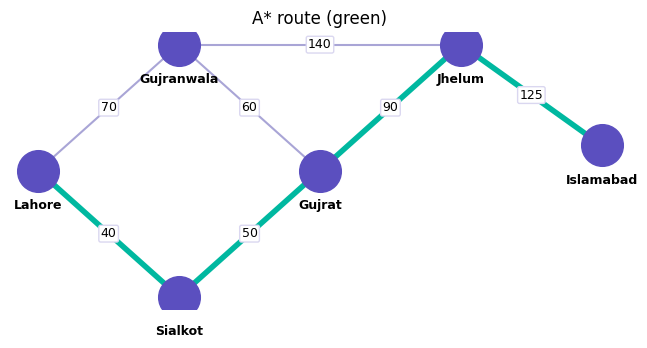

In [38]:
print("LAHORE -> ISLAMABAD")
compare(GraphProblem(LAHORE, "Lahore", "Islamabad"), H_LAHORE)
print("\nLAHORE -> MULTAN")
compare(GraphProblem(MULTAN, "Lahore", "Multan"), H_MULTAN)
draw_graph(LAHORE, POS["LAHORE"], path=astar(GraphProblem(LAHORE,"Lahore","Islamabad"), lambda s: H_LAHORE[s]).path if RESULTS.get("Task 4.2 A*") else None, title="A* route (green)")


**Question 4.3a:** Fill in from the tables above (Lahore → Islamabad):

| | BFS | DFS | UCS | Greedy | A* |
|---|---|---|---|---|---|
| Cost (km) | | | | | |
| Cities checked | | | | | |

**Question 4.3b:** Which algorithms found the cheapest route? Which one checked the *fewest* cities, and was its route the cheapest? What does that tell you about Greedy?
> **Your answer:** _______________________________________________


## Task 4.4 — Is my hint safe? Admissible and consistent hints
From **Lecture 06 — Informed Search**:
- **Admissible:** `h(n) ≤ true remaining cost` for every city; the hint never overestimates. For **A* tree search**, an admissible heuristic guarantees an optimal solution.
- **Consistent:** for every road `a – b` with cost `w`, `h(a) ≤ w + h(b)` (and the reverse direction for an undirected road). This notebook's A* is graph search and does not reopen explored nodes, so a **consistent heuristic** is the condition used to guarantee an optimal route.

The helper below computes the **true remaining cost** from every city to the goal (it runs a cheapest-path search backwards from the goal).


In [39]:
def true_remaining_costs(graph, goal):
    """True cheapest cost from every city to `goal` (given helper)."""
    dist = {n: float("inf") for n in graph}
    dist[goal] = 0
    heap = [(0, goal)]
    while heap:
        d, n = heapq.heappop(heap)
        if d > dist[n]:
            continue
        for m, w in graph[n]:
            if d + w < dist[m]:
                dist[m] = d + w
                heapq.heappush(heap, (dist[m], m))
    return dist

print(true_remaining_costs(LAHORE, "Islamabad"))


{'Lahore': 305, 'Gujranwala': 265, 'Sialkot': 265, 'Gujrat': 215, 'Jhelum': 125, 'Islamabad': 0}


Complete `is_admissible(graph, h, goal)` and `is_consistent(graph, h)` (1 blank each). Both take `h` as a **dictionary** `{city: hint}` and return `True` or `False`.


In [40]:
def is_admissible(graph, h, goal):
    """True if h[n] <= the true remaining cost for EVERY city n."""
    true = true_remaining_costs(graph, goal)
    return all(h[n] <= true[n] for n in graph)       # compare the hint with the ? cost  (true)

def is_consistent(graph, h):
    """True if h[a] <= w + h[b] for EVERY road (a, b, w), in both directions."""
    return all(h[a] <= w + h[b] for a in graph for b, w in graph[a])   # the road cost  (w)


In [41]:
H_LIE   = dict(H_LAHORE, Sialkot=400)    # Extra experiment: Sialkot's hint is exaggerated
H_C     = dict(H_MULTAN, Okara=250)      # Lecture 06 activity: Hint C, Okara's hint exaggerated

def test_4_4():
    assert is_admissible(LAHORE, H_LAHORE, "Islamabad") is True, "H_LAHORE is admissible (every hint is below the true cost)"
    assert is_consistent(LAHORE, H_LAHORE) is True, "H_LAHORE is consistent (all 7 roads pass)"
    assert is_admissible(LAHORE, H_LIE, "Islamabad") is False, "H_LIE gives Sialkot 400 but its true cost is 265, so it is NOT admissible"
    assert is_consistent(LAHORE, H_LIE) is False, "H_LIE is not consistent either"
    assert is_admissible(MULTAN, H_MULTAN, "Multan") is True, "H_MULTAN is admissible"
    assert is_admissible(MULTAN, H_C, "Multan") is False, "Hint C gives Okara 250 but its true cost is 190, so it is NOT admissible"
run_test("Task 4.4 Admissible and consistent", test_4_4)


[PASS] Task 4.4 Admissible and consistent: passed


## Task 4.5 — Experiment: what happens when a hint overestimates?
Run A* with the lecture hint and with the exaggerated hints, then compare the routes and costs. The Sialkot example is an extra experiment; Hint C on the Lahore–Multan map is the example used in the lecture notes.


In [42]:
pbL = GraphProblem(LAHORE, "Lahore", "Islamabad")
pbM = GraphProblem(MULTAN, "Lahore", "Multan")
show("A* with the honest hint        ", astar(pbL, lambda s: H_LAHORE[s]))
show("A* with Sialkot = 400 (a lie)  ", astar(pbL, lambda s: H_LIE[s]))
print()
show("A* Multan, honest hint         ", astar(pbM, lambda s: H_MULTAN[s]))
show("A* Multan, Hint C (Okara 250)  ", astar(pbM, lambda s: H_C[s]))


A* with the honest hint        : found=True  cost=305  checked(6)=['Lahore', 'Gujranwala', 'Sialkot', 'Gujrat', 'Jhelum', 'Islamabad']
   path: Lahore -> Sialkot -> Gujrat -> Jhelum -> Islamabad
A* with Sialkot = 400 (a lie)  : found=True  cost=335  checked(5)=['Lahore', 'Gujranwala', 'Gujrat', 'Jhelum', 'Islamabad']
   path: Lahore -> Gujranwala -> Jhelum -> Islamabad

A* Multan, honest hint         : found=True  cost=300  checked(5)=['Lahore', 'Okara', 'Sahiwal', 'Faisalabad', 'Multan']
   path: Lahore -> Okara -> Sahiwal -> Multan
A* Multan, Hint C (Okara 250)  : found=True  cost=340  checked(4)=['Lahore', 'Faisalabad', 'Khanewal', 'Multan']
   path: Lahore -> Faisalabad -> Khanewal -> Multan


**Question 4.5:** What cost did A* return with each overestimating hint? When the goal was selected, which cities were still waiting in the frontier? Explain how the overestimate changed the route that A* selected.
> **Your answer:** _______________________________________________


## Task 4.6 — Design your own heuristic (additional practice)

For this extra exercise, call the estimate **Hint B**: *“number of roads still to cross × 100”*. This extends the heuristic idea from Lecture 06. The lecture's Lahore–Multan map exercise uses Hint A and the overestimating Hint C.

Complete `hops_heuristic(graph, goal)` (1 blank), returning `{city: 100 × (fewest roads from that city to the goal)}`. Use BFS because fewest roads means fewest steps.


In [43]:
def hops_heuristic(graph, goal, scale=100):
    """h[city] = scale * (fewest roads from city to goal)."""
    h = {}
    for city in graph:
        r = bfs(GraphProblem(graph, city, goal))
        roads = len(r.path) - 1          # cities on the path minus ?  gives the number of roads
        h[city] = scale * roads
    return h


In [44]:
def test_4_6():
    hB = hops_heuristic(MULTAN, "Multan")
    assert hB == {"Lahore":300, "Okara":200, "Faisalabad":200, "Sahiwal":100, "Khanewal":100, "Multan":0}, f"unexpected values: {hB}"
run_test("Task 4.6 Hops heuristic", test_4_6)


[PASS] Task 4.6 Hops heuristic: passed


In [45]:
hB = hops_heuristic(MULTAN, "Multan")
print("Hint B:", hB)
print("Admissible?", is_admissible(MULTAN, hB, "Multan"), "  Consistent?", is_consistent(MULTAN, hB))
show("Greedy with Hint A", greedy(pbM, lambda s: H_MULTAN[s]))
show("Greedy with Hint B", greedy(pbM, lambda s: hB[s]))
show("A*     with Hint A", astar(pbM, lambda s: H_MULTAN[s]))
show("A*     with Hint B", astar(pbM, lambda s: hB[s]))


Hint B: {'Lahore': 300, 'Okara': 200, 'Faisalabad': 200, 'Sahiwal': 100, 'Khanewal': 100, 'Multan': 0}
Admissible? False   Consistent? False
Greedy with Hint A: found=True  cost=340  checked(4)=['Lahore', 'Faisalabad', 'Khanewal', 'Multan']
   path: Lahore -> Faisalabad -> Khanewal -> Multan
Greedy with Hint B: found=True  cost=340  checked(4)=['Lahore', 'Faisalabad', 'Khanewal', 'Multan']
   path: Lahore -> Faisalabad -> Khanewal -> Multan
A*     with Hint A: found=True  cost=300  checked(5)=['Lahore', 'Okara', 'Sahiwal', 'Faisalabad', 'Multan']
   path: Lahore -> Okara -> Sahiwal -> Multan
A*     with Hint B: found=True  cost=300  checked(4)=['Lahore', 'Okara', 'Sahiwal', 'Multan']
   path: Lahore -> Okara -> Sahiwal -> Multan


**Question 4.6:** (a) Is Hint B admissible? Which **cities** break the rule? (b) A* with Hint B still found the cheapest route this time. Does one successful run prove the hint is safe? (c) Hint B gives larger estimates at some cities than Hint A. Why does a larger estimate not automatically make a heuristic better or safe? What did Greedy do with each hint?
> **Your answer:** _______________________________________________


---
# Part 5 — The 8-puzzle: does a better hint really help?
In the Problem Formulation and Informed Search lectures, we met the 8-puzzle (a *toy problem*). A state is a tuple of 9 numbers read row by row; `0` is the blank. Every move costs 1, so a cheapest solution is also a solution with the fewest moves.

```
start = (1,2,4,      goal = (1,2,3,
         7,5,3,               4,5,6,
         0,8,6)               7,8,0)
```
Because our search engines only need `start`, `is_goal` and `successors`, the **same** `bfs`, `ucs`, `greedy` and `astar` you wrote work on the puzzle without any change.


In [46]:
GOAL8 = (1, 2, 3, 4, 5, 6, 7, 8, 0)

class Puzzle8:
    """8-puzzle. State = tuple of 9 numbers (0 is the blank). Every move costs 1."""
    MOVES = [("Up", -3), ("Down", 3), ("Left", -1), ("Right", 1)]
    def __init__(self, start): self.start = start
    def is_goal(self, state): return state == GOAL8
    def successors(self, state):
        i = state.index(0); r, c = divmod(i, 3)
        out = []
        for name, d in self.MOVES:
            if (name == "Up" and r == 0) or (name == "Down" and r == 2) or (name == "Left" and c == 0) or (name == "Right" and c == 2):
                continue
            j = i + d
            s = list(state); s[i], s[j] = s[j], s[i]
            out.append((tuple(s), 1))
        return out

def print_board(state):
    for r in range(3):
        print(" ".join(str(x) if x else "_" for x in state[3*r:3*r+3]))
    print()

START8 = (1, 2, 4, 7, 5, 3, 0, 8, 6)
print_board(START8)


1 2 4
7 5 3
_ 8 6



## Task 5.1 — Two heuristics for the 8-puzzle
Complete the two hints from Lecture 06 (1 blank each):
- `h_misplaced(state)`: the number of tiles (not counting the blank) that are **not** in their goal position;
- `h_manhattan(state)`: for every tile (not the blank), how many squares it is from its goal square (rows + columns), added up.

Check by hand: the board `3 2 1 / 4 5 6 / 7 8 _` has `h_misplaced = 2` and `h_manhattan = 4`.


In [47]:
def h_misplaced(state):
    """Number of tiles (not the blank) that are not in their goal position."""
    count = 0
    for i, tile in enumerate(state):
        if tile != 0 and tile != GOAL8[i]:     # compare with the GOAL board  (GOAL8)
            count = count + 1
    return count

def h_manhattan(state):
    """Sum over tiles (not the blank) of |row - goal_row| + |col - goal_col|."""
    total = 0
    for i, tile in enumerate(state):
        if tile != 0:
            g = GOAL8.index(tile)               # goal position of this tile
            row_diff = abs(i // 3 - g // 3)
            col_diff = abs(i % 3 - g % 3)         # goal column of the tile  (g % 3)
            total = total + row_diff + col_diff
    return total


In [48]:
def test_5_1():
    lec = (3, 2, 1, 4, 5, 6, 7, 8, 0)
    assert h_misplaced(lec) == 2, f"3 2 1 / 4 5 6 / 7 8 _ : misplaced tiles should be 2 (tiles 3 and 1), you got {h_misplaced(lec)}"
    assert h_manhattan(lec) == 4, f"3 2 1 / 4 5 6 / 7 8 _ : Manhattan should be 4, you got {h_manhattan(lec)}"
    bonus = (8, 2, 3, 4, 5, 6, 7, 1, 0)
    assert (h_misplaced(bonus), h_manhattan(bonus)) == (2, 6), "board 8 2 3 / 4 5 6 / 7 1 _ should give (2, 6)"
    assert h_misplaced(GOAL8) == 0 and h_manhattan(GOAL8) == 0, "the goal board must have h = 0"
run_test("Task 5.1 8-puzzle heuristics", test_5_1)


[PASS] Task 5.1 8-puzzle heuristics: passed


## Task 5.2 — Compare the algorithms on the puzzle
Run the cell below. It solves `START8` with BFS, UCS, Greedy (Manhattan), A\* with misplaced tiles and A\* with Manhattan, and prints how many states each one **checked**.


In [49]:
import time
def run_puzzle(start=START8):
    pb8 = Puzzle8(start)
    runs = [("BFS", lambda: bfs(pb8)), ("UCS", lambda: ucs(pb8)),
            ("Greedy (Manhattan)", lambda: greedy(pb8, h_manhattan)),
            ("A* (misplaced)", lambda: astar(pb8, h_misplaced)),
            ("A* (Manhattan)", lambda: astar(pb8, h_manhattan))]
    print(f"{'Algorithm':<20}{'Moves':>7}{'Checked':>9}{'Time(s)':>9}")
    out = {}
    for name, run in runs:
        t = time.time()
        try:
            r = run()
        except (NotImplementedError, NameError, AttributeError):
            print(f"{name:<20}  (not written yet)"); continue
        out[name] = r
        print(f"{name:<20}{r.cost:>7}{len(r.checked):>9}{time.time()-t:>9.2f}")
    return out

puz = run_puzzle()


Algorithm             Moves  Checked  Time(s)
BFS                      12     1217     0.01
UCS                      12     1266     0.01
Greedy (Manhattan)       12      382     0.01
A* (misplaced)           12      110     0.00
A* (Manhattan)           12       51     0.00


In [50]:
def test_5_2():
    bfs_r, h1_r, h2_r = puz["BFS"], puz["A* (misplaced)"], puz["A* (Manhattan)"]
    assert h1_r.cost == bfs_r.cost == h2_r.cost, "BFS and both A* runs must find a shortest solution (same number of moves)"
    assert len(h2_r.checked) < len(bfs_r.checked), "A* with Manhattan should check far fewer states than BFS"
    assert len(h2_r.checked) <= len(h1_r.checked), "Manhattan is the sharper hint, so it should check no more states than misplaced tiles"
run_test("Task 5.2 Puzzle comparison", test_5_2)


[PASS] Task 5.2 Puzzle comparison: passed


In [51]:
# Watch the solution step by step (A* with Manhattan)
sol = puz["A* (Manhattan)"]
for i, board in enumerate(sol.path):
    print(f"Move {i}")
    print_board(board)


Move 0
1 2 4
7 5 3
_ 8 6

Move 1
1 2 4
_ 5 3
7 8 6

Move 2
_ 2 4
1 5 3
7 8 6

Move 3
2 _ 4
1 5 3
7 8 6

Move 4
2 4 _
1 5 3
7 8 6

Move 5
2 4 3
1 5 _
7 8 6

Move 6
2 4 3
1 _ 5
7 8 6

Move 7
2 _ 3
1 4 5
7 8 6

Move 8
_ 2 3
1 4 5
7 8 6

Move 9
1 2 3
_ 4 5
7 8 6

Move 10
1 2 3
4 _ 5
7 8 6

Move 11
1 2 3
4 5 _
7 8 6

Move 12
1 2 3
4 5 6
7 8 _



**Question 5.2:** Fill the table from your run and answer: (a) Why did A\* with Manhattan check fewer states than A\* with misplaced tiles? (b) Both A\* runs returned the same number of moves as BFS. Why?

| Algorithm | Moves | States checked |
|---|---|---|
| BFS | | |
| A\* (misplaced) | | |
| A\* (Manhattan) | | |

> **Your answer:** _______________________________________________


---
# Part 6 — Guided challenge: path-finding on a grid
Games and robots often search on a **grid**. `S` = start, `G` = goal, `#` = wall. A move up, down, left or right costs 1. The same engines work again — we only need a new problem class (given) and a hint.


In [52]:
MAZE = ["S....#......",
        ".###.#.####.",
        ".#...#.#....",
        ".#.###.#.###",
        ".#.....#...G",
        ".#########.#",
        "............"]

class GridProblem:
    """Grid path-finding. State = (row, col). Moves: up, down, left, right (cost 1)."""
    def __init__(self, rows):
        self.rows, self.R, self.C = rows, len(rows), len(rows[0])
        for r, row in enumerate(rows):
            for c, ch in enumerate(row):
                if ch == "S": self.start = (r, c)
                if ch == "G": self.goal = (r, c)
    def is_goal(self, state): return state == self.goal
    def successors(self, state):
        r, c = state
        out = []
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nr, nc = r + dr, c + dc
            if 0 <= nr < self.R and 0 <= nc < self.C and self.rows[nr][nc] != "#":
                out.append(((nr, nc), 1))
        return out

def print_grid(rows, path=(), checked=()):
    """Prints the grid. * = path, . = other free cell, o = checked but not on the path."""
    path, checked = set(path), set(checked)
    for r, row in enumerate(rows):
        line = ""
        for c, ch in enumerate(row):
            if ch in "SG#": line += ch
            elif (r, c) in path: line += "*"
            elif (r, c) in checked: line += "o"
            else: line += ch
        print(line)

maze = GridProblem(MAZE)
print_grid(MAZE)
print("start =", maze.start, " goal =", maze.goal)


S....#......
.###.#.####.
.#...#.#....
.#.###.#.###
.#.....#...G
.#########.#
............
start = (0, 0)  goal = (4, 11)


## Task 6.1 — Manhattan distance for a grid
Complete `manhattan_grid(goal)` (1 blank) that **returns a function** `h(state)` giving `|row − goal_row| + |col − goal_col|`.


In [53]:
def manhattan_grid(goal):
    """Returns a heuristic function h(state) = |row - goal_row| + |col - goal_col|."""
    def h(state):
        return abs(state[0] - goal[0]) + abs(state[1] - goal[1])   # column is index ?  (1)
    return h


In [54]:
def test_6_1():
    h = manhattan_grid((4, 11))
    assert h((4, 11)) == 0, "h(goal) must be 0"
    assert h((0, 0)) == 15, f"h((0,0)) should be 4 + 11 = 15, you got {h((0,0))}"
    r = astar(maze, h)
    assert r.cost == 19, f"A* should find a shortest path of 19 moves, you got {r.cost}"
run_test("Task 6.1 Manhattan on a grid", test_6_1)


[PASS] Task 6.1 Manhattan on a grid: passed


In [55]:
hg = manhattan_grid(maze.goal)
compare(maze, hg)
r = astar(maze, hg)
print("\nA* path (*) and the cells it checked (o):")
print_grid(MAZE, r.path, r.checked)


Algorithm  Cost  Checked  MaxFrontier   Path
BFS          19       40            3   (19 steps)
DFS          19       51            4   (19 steps)
UCS          19       41            3   (19 steps)
Greedy       33       34            3   (33 steps)
A*           19       35            3   (19 steps)

A* path (*) and the cells it checked (o):
Soooo#......
*###o#.####.
*#ooo#.#....
*#o###.#.###
*#ooooo#..*G
*#########*#
***********o


In [56]:
print("Greedy path (*) and checked cells (o):")
rg = greedy(maze, hg)
print_grid(MAZE, rg.path, rg.checked)
print("Greedy cost:", rg.cost)


Greedy path (*) and checked cells (o):
S****#******
.###*#*####*
.#***#*#****
.#*###*#*###
.#*****#***G
.#########.#
............
Greedy cost: 33


**Question 6.1:** Greedy checked fewer cells than A\*, but its path was longer. Look at the picture: where did Greedy get *fooled*?
> **Your answer:** _______________________________________________


## Task 6.2 — What if the hint exaggerates?
Fill the blank to make a hint that is **3 × Manhattan**, then run the cell to see the cost. Is the cost still 19? Is the hint admissible?


In [57]:
h3 = lambda state: 3 * hg(state)        # BLANK: "3 x Manhattan"  (type the number 3)
r3 = astar(maze, h3)
print("A* with 3 x Manhattan: cost =", r3.cost, " checked =", len(r3.checked))


A* with 3 x Manhattan: cost = 19  checked = 37


In [58]:
def test_6_2():
    assert r3 is not None, "run A* with the 3 x Manhattan hint and store the result in r3"
    assert r3.found, "A* should still find a path"
run_test("Task 6.2 Exaggerated hint", test_6_2)


[PASS] Task 6.2 Exaggerated hint: passed


**Question 6.2:** Compare the cost and the number of cells with the honest Manhattan hint (19 moves, 35 cells). Does the answer prove that a 3× hint is safe?
> **Your answer:** _______________________________________________


## Task 6.3 — Extension: a big open field where A\* shines
On a tiny map A\* does not look much better than blind search. On a big open field the hint becomes powerful. Run the cell and fill the table.


In [59]:
def make_open_field(rows=15, cols=30):
    grid = [["." for _ in range(cols)] for _ in range(rows)]
    for r in range(2, rows - 2):
        grid[r][cols // 2] = "#"                 # a wall in the middle, gaps at the top and the bottom
    grid[rows // 2][2] = "S"
    grid[rows // 2][cols - 3] = "G"
    return ["".join(row) for row in grid]

FIELD = make_open_field()
field = GridProblem(FIELD)
hf = manhattan_grid(field.goal)
print_grid(FIELD)
print()
compare(field, hf)


..............................
..............................
...............#..............
...............#..............
...............#..............
...............#..............
...............#..............
..S............#...........G..
...............#..............
...............#..............
...............#..............
...............#..............
...............#..............
..............................
..............................

Algorithm  Cost  Checked  MaxFrontier   Path
BFS          37      431           20   (37 steps)
DFS         377      402          363   (377 steps)
UCS          37      433           20   (37 steps)
Greedy       37       63           63   (37 steps)
A*           37      347           70   (37 steps)


In [60]:
def test_6_3():
    rb, ra = bfs(field), astar(field, hf)
    assert ra.cost == rb.cost, "BFS and A* must find a path of the same (shortest) length"
    assert len(ra.checked) < len(rb.checked), "A* should check fewer cells than BFS on the open field"
run_test("Task 6.3 Open field", test_6_3)


[PASS] Task 6.3 Open field: passed


**Question 6.3:** How many cells did BFS check, and how many did A\*? In one sentence, why is A\* so much better here?
> **Your answer:** _______________________________________________


---
# Part 7 — Reflection and submission

## Which algorithm would you use? (answer in one line each)
| Situation | Your choice and reason |
|---|---|
| 1. Fewest friend-of-friend hops between two people | |
| 2. Cheapest bus + metro fare from home to campus | |
| 3. A quick “good enough” route when the cheapest is not critical | |
| 4. A navigation app that needs the cheapest road route and has straight-line distances | |
| 5. A maze explorer with very little memory | |

## Final check — run this cell before you submit


In [61]:
print("Name:", STUDENT_NAME or "(enter your name in Part 0)", "| Roll no:", ROLL_NO or "(enter your roll number in Part 0)")
print("-" * 60)
passed = sum(RESULTS.values())
total = len(RESULTS)
for name, ok in RESULTS.items():
    print(("[PASS]" if ok else "[CHECK]"), name)
print("-" * 60)
print(f"Auto-tests passed: {passed} / {total}")
print("Before submitting, answer the written questions, save the notebook, and check that all required tests pass.")


Name: (enter your name in Part 0) | Roll no: (enter your roll number in Part 0)
------------------------------------------------------------
[PASS] Task 1.1 Queue
[PASS] Task 1.2 Stack
[PASS] Task 1.3 Priority queue
[PASS] Task 2.1 Path cost
[PASS] Task 2.2 Campus map
[PASS] Task 3.1 BFS (given) works
[PASS] Task 3.2 Degrees of separation
[PASS] Task 3.3 DFS
[PASS] Task 3.4 UCS
[PASS] Task 4.1 Greedy
[PASS] Task 4.2 A*
[PASS] Task 4.4 Admissible and consistent
[PASS] Task 4.6 Hops heuristic
[PASS] Task 5.1 8-puzzle heuristics
[PASS] Task 5.2 Puzzle comparison
[PASS] Task 6.1 Manhattan on a grid
[PASS] Task 6.2 Exaggerated hint
[PASS] Task 6.3 Open field
------------------------------------------------------------
Auto-tests passed: 18 / 18
Before submitting, answer the written questions, save the notebook, and check that all required tests pass.
